In [1]:
# =========================
# Cell 1: Imports
# =========================
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (accuracy_score, confusion_matrix,
                             classification_report, roc_auc_score, roc_curve)

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier

import tensorflow as tf
from tensorflow.keras import Sequential
from tensorflow.keras.layers import Conv1D, Flatten, Dense, Dropout, BatchNormalization

print("TensorFlow:", tf.__version__)


C:\Users\Asus\AppData\Roaming\Python\Python313\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/attr_value.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\Asus\AppData\Roaming\Python\Python313\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/tensor.proto. Please update the gencode to avoid compatibility violations in the next runtime release.
  warnings.warn(
C:\Users\Asus\AppData\Roaming\Python\Python313\site-packages\google\protobuf\runtime_version.py:98: UserWarning: Protobuf gencode version 5.28.3 is exactly one major version older than the runtime version 6.31.1 at tensorflow/core/framework/resource_handle.proto. Please upd

TensorFlow: 2.20.0


In [2]:
# =========================
# Cell 2: Load dataset
# =========================
df = pd.read_csv("creditcard.csv")   # your 555,719 x 23 dataset
print("Original shape:", df.shape)
df.head()


Original shape: (555719, 23)


,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


Original class counts:
is_fraud
0    553574
1      2145
Name: count, dtype: int64

Original class proportions:
is_fraud
0    0.99614
1    0.00386
Name: proportion, dtype: float64


C:\Users\Asus\AppData\Local\Temp\ipykernel_24008\3517204876.py:10: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='is_fraud', data=df, palette='Set1')


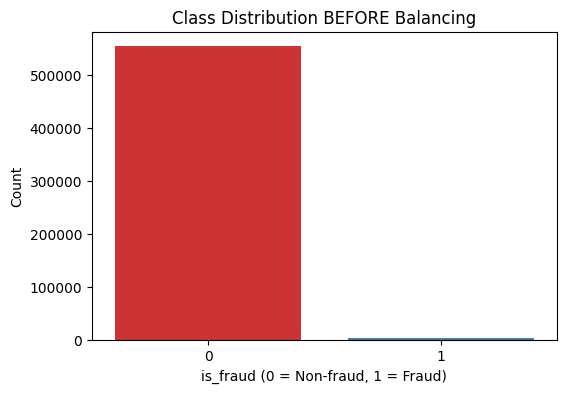

In [3]:
# =========================
# Cell 3: Original class distribution (table + graph)
# =========================
print("Original class counts:")
print(df['is_fraud'].value_counts())
print("\nOriginal class proportions:")
print(df['is_fraud'].value_counts(normalize=True))

plt.figure(figsize=(6,4))
sns.countplot(x='is_fraud', data=df, palette='Set1')
plt.title('Class Distribution BEFORE Balancing')
plt.xlabel('is_fraud (0 = Non-fraud, 1 = Fraud)')
plt.ylabel('Count')
plt.show()


In [4]:
# =========================
# Cell 4: Create 30% fraud / 70% non-fraud balanced dataset
#         Keep total rows same as original (555,719)
# =========================
from sklearn.utils import resample

TOTAL = df.shape[0]
fraud_target = int(TOTAL * 0.30)
non_fraud_target = TOTAL - fraud_target

print("Target rows -> Fraud:", fraud_target, ", Non-fraud:", non_fraud_target)

non_fraud = df[df['is_fraud'] == 0]
fraud = df[df['is_fraud'] == 1]

print("Original non-fraud:", non_fraud.shape[0])
print("Original fraud    :", fraud.shape[0])

non_fraud_balanced = resample(non_fraud,
                              replace=False,
                              n_samples=non_fraud_target,
                              random_state=42)

fraud_balanced = resample(fraud,
                          replace=True,
                          n_samples=fraud_target,
                          random_state=42)

balanced_df = pd.concat([non_fraud_balanced, fraud_balanced]).sample(frac=1, random_state=42)

print("\nBalanced shape:", balanced_df.shape)
print("Balanced counts:")
print(balanced_df['is_fraud'].value_counts())
print("\nBalanced proportions:")
print(balanced_df['is_fraud'].value_counts(normalize=True))

balanced_df.to_csv("balanced_creditcard_30_70.csv", index=False)
print("\nSaved -> balanced_creditcard_30_70.csv")


Target rows -> Fraud: 166715 , Non-fraud: 389004
Original non-fraud: 553574
Original fraud    : 2145

Balanced shape: (555719, 23)
Balanced counts:
is_fraud
0    389004
1    166715
Name: count, dtype: int64

Balanced proportions:
is_fraud
0    0.700001
1    0.299999
Name: proportion, dtype: float64

Saved -> balanced_creditcard_30_70.csv


In [5]:
df.head()

,Unnamed: 0,trans_date_trans_time,cc_num,merchant,category,amt,first,last,gender,street,...,lat,long,city_pop,job,dob,trans_num,unix_time,merch_lat,merch_long,is_fraud
0,0,2020-06-21 12:14:25,2291163933867244,fraud_Kirlin and Sons,personal_care,2.86,Jeff,Elliott,M,351 Darlene Green,...,33.9659,-80.9355,333497,Mechanical engineer,1968-03-19,2da90c7d74bd46a0caf3777415b3ebd3,1371816865,33.986391,-81.200714,0
1,1,2020-06-21 12:14:33,3573030041201292,fraud_Sporer-Keebler,personal_care,29.84,Joanne,Williams,F,3638 Marsh Union,...,40.3207,-110.4360,302,"Sales professional, IT",1990-01-17,324cc204407e99f51b0d6ca0055005e7,1371816873,39.450498,-109.960431,0
2,2,2020-06-21 12:14:53,3598215285024754,"fraud_Swaniawski, Nitzsche and Welch",health_fitness,41.28,Ashley,Lopez,F,9333 Valentine Point,...,40.6729,-73.5365,34496,"Librarian, public",1970-10-21,c81755dbbbea9d5c77f094348a7579be,1371816893,40.495810,-74.196111,0
3,3,2020-06-21 12:15:15,3591919803438423,fraud_Haley Group,misc_pos,60.05,Brian,Williams,M,32941 Krystal Mill Apt. 552,...,28.5697,-80.8191,54767,Set designer,1987-07-25,2159175b9efe66dc301f149d3d5abf8c,1371816915,28.812398,-80.883061,0
4,4,2020-06-21 12:15:17,3526826139003047,fraud_Johnston-Casper,travel,3.19,Nathan,Massey,M,5783 Evan Roads Apt. 465,...,44.2529,-85.0170,1126,Furniture designer,1955-07-06,57ff021bd3f328f8738bb535c302a31b,1371816917,44.959148,-85.884734,0


C:\Users\Asus\AppData\Local\Temp\ipykernel_24008\2274363149.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='is_fraud', data=balanced_df, palette='Set2')


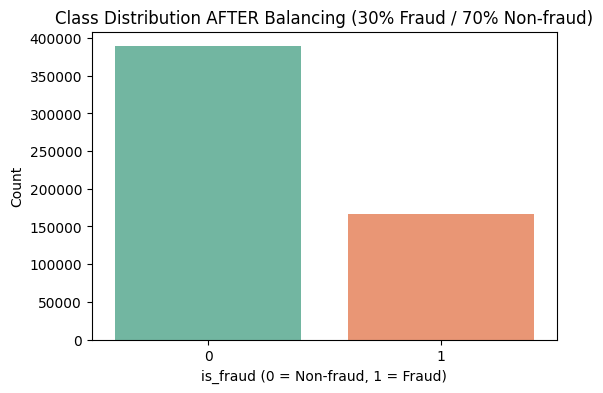

In [6]:
# =========================
# Cell 5: Plot balanced class distribution
# =========================
plt.figure(figsize=(6,4))
sns.countplot(x='is_fraud', data=balanced_df, palette='Set2')
plt.title('Class Distribution AFTER Balancing (30% Fraud / 70% Non-fraud)')
plt.xlabel('is_fraud (0 = Non-fraud, 1 = Fraud)')
plt.ylabel('Count')
plt.show()


In [7]:
# =========================
# Cell 6: Feature/target definition using YOUR columns
# Columns present (from your file):
# Unnamed: 0, trans_date_trans_time, cc_num, merchant, category, amt,
# first, last, gender, street, city, state, zip, lat, long, city_pop,
# job, dob, trans_num, unix_time, merch_lat, merch_long, is_fraud
# =========================
target_col = 'is_fraud'

# Drop index-like column only
cols_to_drop = ['Unnamed: 0'] if 'Unnamed: 0' in balanced_df.columns else []

X_raw = balanced_df.drop(columns=cols_to_drop + [target_col])
y = balanced_df[target_col]

print("Raw feature columns:", X_raw.columns.tolist())
print("Raw feature shape:", X_raw.shape, "| Target shape:", y.shape)


Raw feature columns: ['trans_date_trans_time', 'cc_num', 'merchant', 'category', 'amt', 'first', 'last', 'gender', 'street', 'city', 'state', 'zip', 'lat', 'long', 'city_pop', 'job', 'dob', 'trans_num', 'unix_time', 'merch_lat', 'merch_long']
Raw feature shape: (555719, 21) | Target shape: (555719,)


In [12]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer

# ... same X_work, num_cols, cat_cols as before ...

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            max_categories=20,
            sparse_output=True    # <-- use this, not `sparse=`
        ), cat_cols),
    ],
    sparse_threshold=0.3
)


In [14]:
# =========================
# Cell 8: Helper functions (evaluation + confusion matrix)
# =========================
def evaluate_model(name, y_true, y_pred, y_proba=None):
    print(f"\n===== {name} =====")
    print("Accuracy:", accuracy_score(y_true, y_pred))
    print("Confusion Matrix:\n", confusion_matrix(y_true, y_pred))
    print("Classification Report:\n", classification_report(y_true, y_pred))
    if y_proba is not None:
        print("ROC AUC:", roc_auc_score(y_true, y_proba))

def plot_confusion_matrix(y_true, y_pred, title):
    cm = confusion_matrix(y_true, y_pred)
    plt.figure(figsize=(4,3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=['Non-Fraud', 'Fraud'],
                yticklabels=['Non-Fraud', 'Fraud'])
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title(title)
    plt.show()


In [16]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.model_selection import train_test_split

# 1. Drop clearly text / ID columns
drop_cols = [
    'trans_date_trans_time',
    'first', 'last',
    'street', 'city', 'job',
    'dob',
    'trans_num'
]
X_work = X_raw.drop(columns=[c for c in drop_cols if c in X_raw.columns])

# 2. Split by dtype
num_cols = X_work.select_dtypes(include=['number']).columns.tolist()
cat_cols = X_work.select_dtypes(include=['object', 'category']).columns.tolist()

print("Numeric columns:", num_cols)
print("Categorical columns:", cat_cols)

# 3. Preprocessor
preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(
            handle_unknown="ignore",
            max_categories=20,
            sparse_output=True   # important for your sklearn version
        ), cat_cols),
    ],
    sparse_threshold=0.3
)

# 4. Fit-transform, then split
X_encoded = preprocess.fit_transform(X_work)
print("Encoded type:", type(X_encoded), "shape:", X_encoded.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

# 5. Scale
scaler = StandardScaler(with_mean=False)
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Train shape (scaled):", X_train_scaled.shape, "Test shape:", X_test_scaled.shape)


Numeric columns: ['cc_num', 'amt', 'zip', 'lat', 'long', 'city_pop', 'unix_time', 'merch_lat', 'merch_long']
Categorical columns: ['merchant', 'category', 'gender', 'state']
Encoded type: <class 'scipy.sparse._csr.csr_matrix'> shape: (555719, 65)
Train shape (scaled): (444575, 65) Test shape: (111144, 65)



===== Logistic Regression =====
Accuracy: 0.9015151515151515
Confusion Matrix:
 [[76015  1786]
 [ 9160 24183]]
Classification Report:
               precision    recall  f1-score   support

           0       0.89      0.98      0.93     77801
           1       0.93      0.73      0.82     33343

    accuracy                           0.90    111144
   macro avg       0.91      0.85      0.87    111144
weighted avg       0.90      0.90      0.90    111144

ROC AUC: 0.9064179468827038


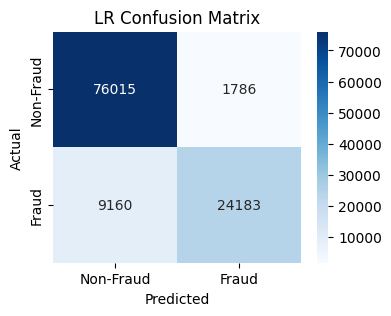

In [17]:
# =========================
# Cell 9: Logistic Regression
# =========================
lr = LogisticRegression(max_iter=1000, n_jobs=-1)
lr.fit(X_train_scaled, y_train)

y_pred_lr = lr.predict(X_test_scaled)
y_proba_lr = lr.predict_proba(X_test_scaled)[:, 1]

evaluate_model("Logistic Regression", y_test, y_pred_lr, y_proba_lr)
plot_confusion_matrix(y_test, y_pred_lr, "LR Confusion Matrix")



===== Random Forest =====
Accuracy: 0.9995771251709494
Confusion Matrix:
 [[77754    47]
 [    0 33343]]
Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00     77801
           1       1.00      1.00      1.00     33343

    accuracy                           1.00    111144
   macro avg       1.00      1.00      1.00    111144
weighted avg       1.00      1.00      1.00    111144

ROC AUC: 1.0


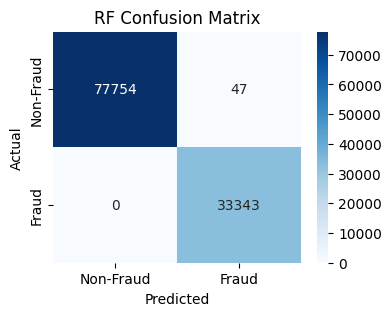

In [18]:
# =========================
# Cell 11: Random Forest
# =========================
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]

evaluate_model("Random Forest", y_test, y_pred_rf, y_proba_rf)
plot_confusion_matrix(y_test, y_pred_rf, "RF Confusion Matrix")



===== XGBoost =====
Accuracy: 0.987403728496365
Confusion Matrix:
 [[76921   880]
 [  520 32823]]
Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.99      0.99     77801
           1       0.97      0.98      0.98     33343

    accuracy                           0.99    111144
   macro avg       0.98      0.99      0.99    111144
weighted avg       0.99      0.99      0.99    111144

ROC AUC: 0.9988871976243224


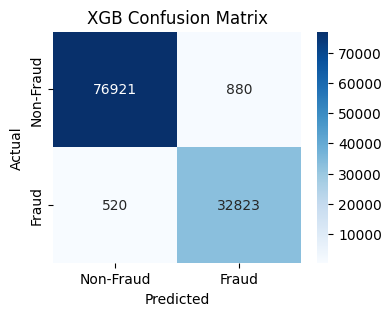

In [19]:
# =========================
# Cell 12: XGBoost
# =========================
xgb = XGBClassifier(
    objective='binary:logistic',
    max_depth=2,
    n_estimators=200,
    learning_rate=0.6,
    subsample=0.6,
    n_jobs=-1,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]

evaluate_model("XGBoost", y_test, y_pred_xgb, y_proba_xgb)
plot_confusion_matrix(y_test, y_pred_xgb, "XGB Confusion Matrix")


In [21]:
# Decision Tree
dt = DecisionTreeClassifier(random_state=42)
dt.fit(X_train, y_train)

y_pred_dt = dt.predict(X_test)
y_proba_dt = dt.predict_proba(X_test)[:, 1]


In [22]:
# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred_rf = rf.predict(X_test)
y_proba_rf = rf.predict_proba(X_test)[:, 1]


In [ ]:
# XGBoost
xgb = XGBClassifier(
    objective='binary:logistic',
    max_depth=2,
    n_estimators=200,
    learning_rate=0.6,
    subsample=0.6,
    n_jobs=-1,
    random_state=42,
    eval_metric='logloss'
)
xgb.fit(X_train, y_train)

y_pred_xgb = xgb.predict(X_test)
y_proba_xgb = xgb.predict_proba(X_test)[:, 1]


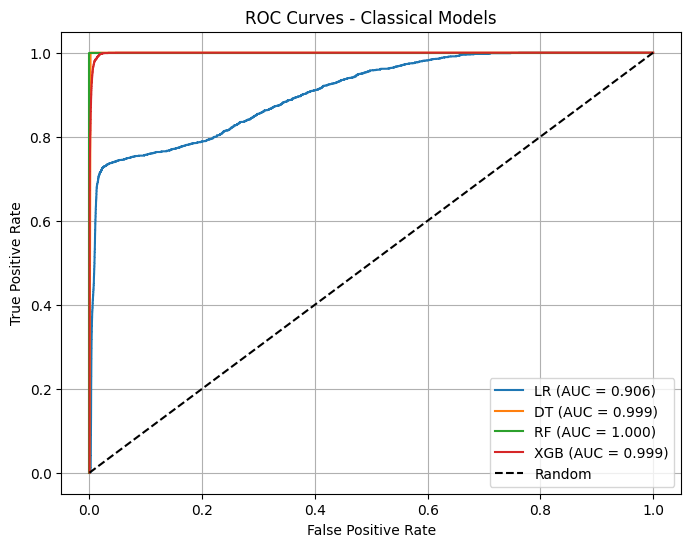

In [ ]:

plt.figure(figsize=(8,6))

for name, y_proba in [
    ("LR",  y_proba_lr),
    ("DT",  y_proba_dt),
    ("RF",  y_proba_rf),
    ("XGB", y_proba_xgb),
]:
    fpr, tpr, _ = roc_curve(y_test, y_proba)
    auc = roc_auc_score(y_test, y_proba)
    plt.plot(fpr, tpr, label=f"{name} (AUC = {auc:.3f})")

plt.plot([0,1], [0,1], 'k--', label='Random')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curves - Classical Models')
plt.legend()
plt.grid(True)
plt.show()


In [26]:
# =========================
# Cell 14: Prepare data for CNN (fix)
# =========================

# 1) Convert sparse -> dense (NumPy arrays)
X_train_dense = X_train_scaled.toarray()
X_test_dense  = X_test_scaled.toarray()

print("Dense train shape:", X_train_dense.shape)
print("Dense test shape :", X_test_dense.shape)

# 2) Reshape to 3D for Conv1D: (samples, timesteps/features, channels)
X_train_cnn = X_train_dense.reshape(X_train_dense.shape[0], X_train_dense.shape[1], 1)
X_test_cnn  = X_test_dense.reshape(X_test_dense.shape[0],  X_test_dense.shape[1],  1)

print("CNN train shape:", X_train_cnn.shape)
print("CNN test shape :", X_test_cnn.shape)


Dense train shape: (444575, 65)
Dense test shape : (111144, 65)
CNN train shape: (444575, 65, 1)
CNN test shape : (111144, 65, 1)


In [27]:
# =========================
# Cell 15: Define CNN model
# =========================
model = Sequential([
    Conv1D(filters=32, kernel_size=2, activation='relu', input_shape=(X_train_cnn.shape[1], 1)),
    BatchNormalization(),
    Dropout(0.2),

    Conv1D(filters=64, kernel_size=2, activation='relu'),
    BatchNormalization(),
    Dropout(0.2),

    Flatten(),
    Dense(64, activation='relu'),
    Dropout(0.5),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.0001),
              loss='binary_crossentropy',
              metrics=['accuracy'])

model.summary()


C:\Users\Asus\AppData\Roaming\Python\Python313\site-packages\keras\src\layers\convolutional\base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                 │ (None, 64, 32)         │            96 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64, 32)         │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 64, 32)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv1d_1 (Conv1D)               │ (None, 63, 64)         │         4,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 63, 64)         │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 63, 64)         │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 4032)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       258,112 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 262,817 (1.00 MB)

 Trainable params: 262,625 (1.00 MB)

 Non-trainable params: 192 (768.00 B)

In [28]:
# =========================
# Cell 16: Train CNN
# =========================
history = model.fit(
    X_train_cnn, y_train,
    validation_split=0.2,
    epochs=20,
    batch_size=256,
    verbose=1
)


Epoch 1/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 32s 21ms/step - accuracy: 0.7586 - loss: 0.5378 - val_accuracy: 0.8548 - val_loss: 0.3547
Epoch 2/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 26s 18ms/step - accuracy: 0.8916 - loss: 0.3107 - val_accuracy: 0.9136 - val_loss: 0.2381
Epoch 3/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9054 - loss: 0.2634 - val_accuracy: 0.9146 - val_loss: 0.2172
Epoch 4/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9103 - loss: 0.2431 - val_accuracy: 0.9157 - val_loss: 0.2096
Epoch 5/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9124 - loss: 0.2320 - val_accuracy: 0.9165 - val_loss: 0.2010
Epoch 6/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9139 - loss: 0.2245 - val_accuracy: 0.9173 - val_loss: 0.1946
Epoch 7/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 27s 19ms/step - accuracy: 0.9150 - loss: 0.2189 - val_accuracy: 0.9174 - val_loss: 0.1905
Epoch 8/20
1390/1390 ━━━━━━━━━━━━━━━━━━━━ 26s 19ms/step - accuracy: 0.9155 -

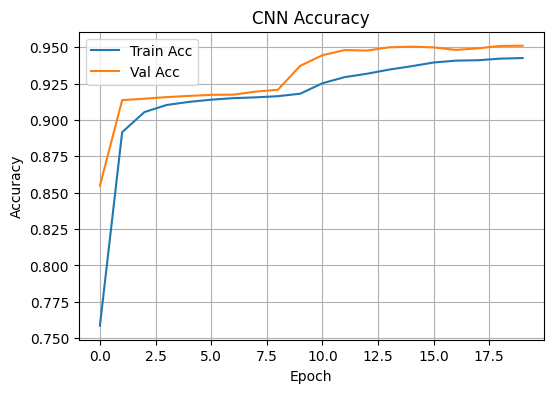

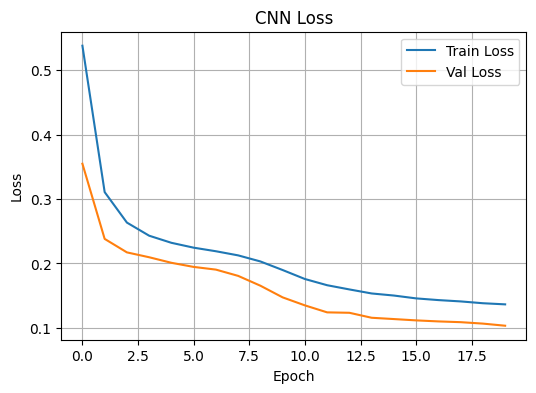

In [29]:
# =========================
# Cell 17: CNN training curves (accuracy & loss)
# =========================
plt.figure(figsize=(6,4))
plt.plot(history.history['accuracy'], label='Train Acc')
plt.plot(history.history['val_accuracy'], label='Val Acc')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('CNN Accuracy')
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(6,4))
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Val Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('CNN Loss')
plt.legend()
plt.grid(True)
plt.show()


3474/3474 ━━━━━━━━━━━━━━━━━━━━ 5s 1ms/step

===== CNN =====
Accuracy: 0.952647016483121
Confusion Matrix:
 [[76781  1020]
 [ 4243 29100]]
Classification Report:
               precision    recall  f1-score   support

           0       0.95      0.99      0.97     77801
           1       0.97      0.87      0.92     33343

    accuracy                           0.95    111144
   macro avg       0.96      0.93      0.94    111144
weighted avg       0.95      0.95      0.95    111144

ROC AUC: 0.9930343813101233


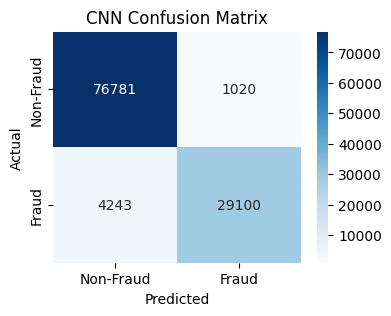

In [30]:
# =========================
# Cell 18: Evaluate CNN + confusion matrix
# =========================
y_proba_cnn = model.predict(X_test_cnn).ravel()
y_pred_cnn = (y_proba_cnn >= 0.5).astype(int)

evaluate_model("CNN", y_test, y_pred_cnn, y_proba_cnn)
plot_confusion_matrix(y_test, y_pred_cnn, "CNN Confusion Matrix")


In [31]:
# =========================
# Cell 19: Compare model accuracies
# =========================
results = pd.DataFrame({
    "Model": ["LR", "DT", "RF", "XGB", "CNN"],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf),
        accuracy_score(y_test, y_pred_xgb),
        accuracy_score(y_test, y_pred_cnn),
    ]
})

results


,Model,Accuracy
0,LR,0.901515
1,DT,0.998659
2,RF,0.999577
3,XGB,0.987404
4,CNN,0.952647
